# GUIDE Dataset — Standalone XGBoost Baseline

Target: `IncidentGrade` (TruePositive / BenignPositive / FalsePositive), 3-class classification.

Scope for this notebook:
- Train and evaluate **XGBoost only**, as a fourth baseline alongside the existing LightGBM, Logistic Regression, and CatBoost results — no ensembling here.
- Reuse the exact same cleaned dataset, audited feature set, and train/validation split saved by the LightGBM notebook (`guide-lightgbm-baseline`), mounted here via `kernel_sources`. Row alignment and `(OrgId, IncidentId)` group non-overlap are re-verified, not assumed.
- XGBoost's own categorical support (`enable_categorical=True` with pandas `category` dtype, tree_method=`hist`) is used directly on the raw categorical values — this notebook does **not** reuse Logistic Regression's one-hot encoded sparse matrix. Category mappings are fit on the training split only; validation values unseen during training become missing, handled the same way as native numeric NaNs.
- API usage (constructor vs. `fit()`-time `early_stopping_rounds`) is detected and adapted to the installed XGBoost version at runtime.
- The official `GUIDE_Test.csv` is **not loaded** — it stays untouched for a later, unbiased final comparison across models.

In [1]:
import os, glob, time, json, warnings, gc
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

import xgboost as xgb
from sklearn.metrics import (
    accuracy_score, f1_score, classification_report, confusion_matrix
)

warnings.filterwarnings('ignore', category=FutureWarning)
pd.set_option('display.max_columns', 100)
sns.set_theme(style='whitegrid')
RANDOM_STATE = 42

OUT_DIR = '/kaggle/working/xgboost'
os.makedirs(OUT_DIR, exist_ok=True)

t0 = time.time()
def lap(msg):
    print(f'[{time.time() - t0:7.1f}s] {msg}')

XGB_VERSION_STR = xgb.__version__
XGB_VERSION = tuple(int(x) for x in XGB_VERSION_STR.split('.')[:2])
lap(f'Installed xgboost version: {XGB_VERSION_STR}')

[    0.0s] Installed xgboost version: 3.4.1


## 1. Load data and reproduce the LightGBM notebook's cleaning

Only `GUIDE_Train.csv` is loaded. The exact same cleaning steps as the LightGBM notebook (drop duplicate rows, then drop rows with a missing target) are applied, in the same order, so this produces the identical row set (by `Id`) that `split_assignment.csv` was built from. A fresh sequential `row_id` is also assigned right after cleaning — it is deterministic given identical input/cleaning, so it lines up with the same column saved by the other notebooks, and is saved with validation predictions below as a stable join key for future ensembling.

In [2]:
matches = glob.glob('/kaggle/input/**/GUIDE_Train.csv', recursive=True)
if not matches:
    raise FileNotFoundError('GUIDE_Train.csv not found under /kaggle/input')
DATA_DIR = os.path.dirname(matches[0])
lap(f'Using DATA_DIR = {DATA_DIR}')

TARGET = 'IncidentGrade'

df = pd.read_csv(f'{DATA_DIR}/GUIDE_Train.csv')
lap(f'Loaded raw train = {df.shape}')

df = df.drop_duplicates().reset_index(drop=True)
lap(f'After dropping duplicate rows: {df.shape}')

df = df.dropna(subset=[TARGET]).reset_index(drop=True)
lap(f'After dropping rows with missing target: {df.shape}')

df['row_id'] = np.arange(len(df))

assert df[TARGET].notna().all()
print('Class distribution:')
print(df[TARGET].value_counts())

[    0.4s] Using DATA_DIR = /kaggle/input/datasets/Microsoft/microsoft-security-incident-prediction
[   70.9s] Loaded raw train = (9516837, 45)
[  117.6s] After dropping duplicate rows: (9494278, 45)
[  123.7s] After dropping rows with missing target: (9442956, 45)
Class distribution:
IncidentGrade
BenignPositive    4110748
TruePositive      3302644
FalsePositive     2029564
Name: count, dtype: int64


## 2. Reuse the audited feature set from the LightGBM notebook

`preprocessing_info.json` (saved by `guide-lightgbm-baseline`, mounted here as a kernel source) records the leakage review already performed: identifiers/hashes excluded, `ActionGrouped`/`ActionGranular` excluded as remediation-action leakage, and `SuspicionLevel`/`LastVerdict` reviewed and kept under the documented assumption that they are automated, pre-triage detection outputs rather than a restatement of the final grade. **That assumption is not re-verified here** — it remains an open, unresolved question about exact prediction-time availability, carried over unchanged from the LightGBM, Logistic Regression, and CatBoost notebooks. The feature set itself is identical (same 19 raw columns), so this result is directly comparable to the other three baselines on that axis; what differs is purely how the 5 numeric-but-really-categorical columns are *encoded* (see section 5).

In [3]:
prep_matches = glob.glob('/kaggle/input/**/preprocessing_info.json', recursive=True)
if not prep_matches:
    raise FileNotFoundError('preprocessing_info.json not found under /kaggle/input — '
                            'check that kernel_sources includes guide-lightgbm-baseline')
with open(prep_matches[0]) as f:
    lgb_preprocessing_info = json.load(f)
lap(f'Loaded preprocessing_info.json from {prep_matches[0]}')

CATEGORICAL_COLS = lgb_preprocessing_info['categorical_cols']
NUMERIC_COLS = lgb_preprocessing_info['numeric_cols']
ID_LIKE_COLS = lgb_preprocessing_info['excluded_id_cols']
LEAKAGE_COLS = lgb_preprocessing_info['excluded_leakage_cols']
GROUP_COLS = lgb_preprocessing_info['group_cols']
FEATURES = CATEGORICAL_COLS + NUMERIC_COLS

print('Categorical features (reused):', len(CATEGORICAL_COLS), CATEGORICAL_COLS)
print('Numeric features (reused):', len(NUMERIC_COLS), NUMERIC_COLS)
print('Excluded as identifiers/hashes:', len(ID_LIKE_COLS))
print('Excluded as remediation-action leakage:', LEAKAGE_COLS)
print('Total reused features:', len(FEATURES))
assert set(FEATURES) == set(lgb_preprocessing_info['features']), 'Feature set mismatch vs LightGBM notebook!'

# Drop every raw column we will never use, now that dedup/target-cleaning already ran on the
# full column set. This happens *after* the cleaning above, so it does not change which rows
# survive (still identical to the other notebooks' row set) — it only frees memory those
# unused high-cardinality identifier/hash columns were holding before the heavier steps below.
DERIVED_COLS = ['Hour', 'DayOfWeek', 'MitreCount', 'MitrePrimary']
RAW_NEEDED_COLS = ['row_id', 'Id', 'OrgId', 'IncidentId', TARGET, 'Timestamp', 'MitreTechniques'] + \
    [c for c in FEATURES if c not in DERIVED_COLS]
before_cols = df.shape[1]
df = df[RAW_NEEDED_COLS].copy()
gc.collect()
lap(f'Dropped unused raw columns: {before_cols} -> {df.shape[1]} columns, {df.shape[0]} rows unchanged')

[  125.2s] Loaded preprocessing_info.json from /kaggle/input/notebooks/towsifhassan1132/guide-lightgbm-baseline/preprocessing_info.json
Categorical features (reused): 11 ['Category', 'EntityType', 'EvidenceRole', 'ResourceType', 'Roles', 'OSFamily', 'OSVersion', 'AntispamDirection', 'SuspicionLevel', 'LastVerdict', 'MitrePrimary']
Numeric features (reused): 8 ['DetectorId', 'AlertTitle', 'CountryCode', 'State', 'City', 'Hour', 'DayOfWeek', 'MitreCount']
Excluded as identifiers/hashes: 25
Excluded as remediation-action leakage: ['ActionGrouped', 'ActionGranular']
Total reused features: 19
[  129.2s] Dropped unused raw columns: 46 -> 22 columns, 9442956 rows unchanged


## 3. Feature engineering (identical to the other notebooks)

`Timestamp` → `Hour`/`DayOfWeek`; `MitreTechniques` (semicolon-separated string) → count + primary technique. Same logic, same column names.

In [4]:
df['Timestamp'] = pd.to_datetime(df['Timestamp'], errors='coerce')
df['Hour'] = df['Timestamp'].dt.hour
df['DayOfWeek'] = df['Timestamp'].dt.dayofweek

mitre = df['MitreTechniques'].fillna('')
df['MitreCount'] = mitre.apply(lambda s: 0 if s == '' else len(s.split(';')))
df['MitrePrimary'] = mitre.apply(lambda s: s.split(';')[0] if s != '' else 'None')

lap(f'Engineered features. Feature count: {len(FEATURES)}')

[  149.5s] Engineered features. Feature count: 19


## 4. Load and verify the saved train/validation split

`split_assignment.csv` (also mounted via `kernel_sources`) is reused by `Id` — the split is **not recomputed**. `Id` is **not** a unique per-row key in this dataset — it is shared by every row belonging to the same incident (its `nunique` equals the LightGBM run's `n_unique_groups`). Every row sharing an `Id` was already verified (in the Logistic Regression and CatBoost notebooks) to share the same `split` label, so deduplicating on `Id` before building the lookup is safe. Row alignment (every row gets exactly one split label, row count unchanged) and zero `(OrgId, IncidentId)` overlap between train and validation are both re-verified rather than assumed.

In [5]:
split_matches = glob.glob('/kaggle/input/**/split_assignment.csv', recursive=True)
if not split_matches:
    raise FileNotFoundError('split_assignment.csv not found under /kaggle/input — '
                            'check that kernel_sources includes guide-lightgbm-baseline')
split_assignment = pd.read_csv(split_matches[0], usecols=['Id', 'split'])
lap(f'Loaded split_assignment.csv from {split_matches[0]} ({len(split_assignment)} rows)')

n_id_conflicts = split_assignment.groupby('Id')['split'].nunique().gt(1).sum()
assert n_id_conflicts == 0, f'{n_id_conflicts} Id values map to more than one split label!'
split_lookup = split_assignment.drop_duplicates(subset=['Id']).set_index('Id')['split']
assert split_lookup.index.is_unique
del split_assignment
gc.collect()

before_rows = len(df)
df['split'] = df['Id'].map(split_lookup)
del split_lookup
gc.collect()

n_missing_split = df['split'].isna().sum()
assert n_missing_split == 0, (
    f'Row alignment check FAILED: {n_missing_split} of {before_rows} cleaned rows got no split label. '
    'The cleaning in this notebook no longer matches the LightGBM notebook.'
)
assert len(df) == before_rows
assert df['split'].isin(['train', 'val']).all()
lap('Row alignment verified: every cleaned row received exactly one split label.')

group_key = df['OrgId'].astype(str) + '_' + df['IncidentId'].astype(str)
train_groups = set(group_key[df['split'] == 'train'])
val_groups = set(group_key[df['split'] == 'val'])
overlap = train_groups & val_groups
assert len(overlap) == 0, 'Group leakage between train and validation!'
lap(f'(OrgId, IncidentId) group overlap between train/val = {len(overlap)} (verified zero)')

print(df.groupby('split')[TARGET].value_counts())
print(f"Train rows: {(df['split']=='train').sum()}  Val rows: {(df['split']=='val').sum()}")

[  153.7s] Loaded split_assignment.csv from /kaggle/input/notebooks/towsifhassan1132/guide-lightgbm-baseline/split_assignment.csv (9442956 rows)
[  157.5s] Row alignment verified: every cleaned row received exactly one split label.
[  169.9s] (OrgId, IncidentId) group overlap between train/val = 0 (verified zero)
split  IncidentGrade 
train  BenignPositive    3288682
       TruePositive      2613852
       FalsePositive     1615837
val    BenignPositive     822066
       TruePositive       688792
       FalsePositive      413727
Name: count, dtype: int64
Train rows: 7518371  Val rows: 1924585


## 5. Categorical handling for XGBoost (native, fit on train only)

Like CatBoost, nothing here is one-hot encoded. All 16 categorical-type columns (11 original categoricals + `DetectorId`/`AlertTitle`/`CountryCode`/`State`/`City`, which are category-coded identifiers rather than continuous quantities) are cast to pandas `category` dtype and passed to `XGBClassifier(enable_categorical=True, tree_method='hist')`, which natively splits on categorical values without one-hot expansion.

To avoid leakage, the set of categories for each column is **learned from the training split only** (plus the `'Missing'` placeholder). Applying that fixed category list to the validation split means any validation value never seen in training is **not** silently coerced into some other category — pandas turns it into `NaN`, which XGBoost's `hist` tree method already handles natively as a missing value (the same mechanism used for the genuinely-missing numeric columns), so unseen categories are handled consistently rather than crashing or being guessed.

The 3 remaining numeric columns (`Hour`, `DayOfWeek`, `MitreCount`) are left as plain floats with `NaN` kept as-is.

In [6]:
ID_LIKE_NUMERIC_AS_CATEGORICAL = ['DetectorId', 'AlertTitle', 'CountryCode', 'State', 'City']
CAT_FEATURES = CATEGORICAL_COLS + ID_LIKE_NUMERIC_AS_CATEGORICAL
NUMERIC_FEATURES = [c for c in NUMERIC_COLS if c not in ID_LIKE_NUMERIC_AS_CATEGORICAL]

assert set(CAT_FEATURES + NUMERIC_FEATURES) == set(FEATURES)
print('Native categorical columns:', len(CAT_FEATURES), CAT_FEATURES)
print('Numeric columns:', NUMERIC_FEATURES)

train_mask = df['split'] == 'train'
val_mask = df['split'] == 'val'

n_unseen_total = 0
for col in CAT_FEATURES:
    df[col] = df[col].fillna('Missing').astype(str)
    train_categories = sorted(df.loc[train_mask, col].unique())
    df[col] = pd.Categorical(df[col], categories=train_categories)
    n_unseen = df.loc[val_mask, col].isna().sum()
    n_unseen_total += n_unseen
    if n_unseen > 0:
        print(f'  {col}: {len(train_categories)} train categories, '
              f'{n_unseen} val rows have a category unseen in training -> treated as missing')
lap(f'Fit {len(CAT_FEATURES)} categorical mappings on training data only; '
    f'{n_unseen_total} total val cells mapped to missing for unseen categories')

for col in NUMERIC_FEATURES:
    df[col] = pd.to_numeric(df[col], errors='coerce')

target_classes = sorted(df[TARGET].unique())
target_map = {v: i for i, v in enumerate(target_classes)}
inv_target_map = {i: v for v, i in target_map.items()}
df['_target'] = df[TARGET].map(target_map)
print('Target classes:', target_map)

X_train, y_train = df.loc[train_mask, FEATURES], df.loc[train_mask, '_target']
X_val, y_val = df.loc[val_mask, FEATURES], df.loc[val_mask, '_target']
val_row_ids = df.loc[val_mask, ['row_id', 'Id', 'OrgId', 'IncidentId']].reset_index(drop=True)
n_classes = len(target_map)
lap(f'X_train={X_train.shape}, X_val={X_val.shape}, n_classes={n_classes}')

Native categorical columns: 16 ['Category', 'EntityType', 'EvidenceRole', 'ResourceType', 'Roles', 'OSFamily', 'OSVersion', 'AntispamDirection', 'SuspicionLevel', 'LastVerdict', 'MitrePrimary', 'DetectorId', 'AlertTitle', 'CountryCode', 'State', 'City']
Numeric columns: ['Hour', 'DayOfWeek', 'MitreCount']
  OSVersion: 50 train categories, 13 val rows have a category unseen in training -> treated as missing
  MitrePrimary: 323 train categories, 16 val rows have a category unseen in training -> treated as missing
  DetectorId: 7350 train categories, 5513 val rows have a category unseen in training -> treated as missing
  AlertTitle: 69123 train categories, 112090 val rows have a category unseen in training -> treated as missing
  CountryCode: 228 train categories, 15 val rows have a category unseen in training -> treated as missing
  State: 1318 train categories, 63 val rows have a category unseen in training -> treated as missing
  City: 8596 train categories, 908 val rows have a catego

## 6. Train XGBoost with validation-based early stopping

`tree_method='hist'` is the CPU-compatible histogram algorithm, run here with `enable_categorical=True` so the native categorical columns above are split on directly. `early_stopping_rounds` moved from a `fit()`-time argument to an `XGBClassifier` constructor argument across XGBoost versions (1.6+), so the constructor form is tried first and the code falls back to the older `fit()`-time form on `TypeError` — adapting to whichever XGBoost is actually installed on Kaggle rather than assuming one API. Progress is printed every `verbose` rounds, and `evals_result()` is kept for the training/validation log-loss curve plotted below. No hyperparameter search is performed; all settings are exactly as specified.

In [7]:
MODEL_KWARGS = dict(
    objective='multi:softprob',
    num_class=n_classes,
    tree_method='hist',
    n_estimators=500,
    learning_rate=0.1,
    max_depth=6,
    random_state=42,
    eval_metric='mlogloss',
    enable_categorical=True,
    n_jobs=-1,
)

train_start = time.time()
try:
    model = xgb.XGBClassifier(**MODEL_KWARGS, early_stopping_rounds=50)
    model.fit(X_train, y_train, eval_set=[(X_train, y_train), (X_val, y_val)], verbose=50)
    early_stopping_api = 'constructor (XGBClassifier(early_stopping_rounds=...))'
except TypeError as e:
    lap(f'Constructor-style early_stopping_rounds not supported ({e}); falling back to fit()-time arg')
    model = xgb.XGBClassifier(**MODEL_KWARGS)
    model.fit(X_train, y_train, eval_set=[(X_train, y_train), (X_val, y_val)],
              early_stopping_rounds=50, verbose=50)
    early_stopping_api = 'fit(early_stopping_rounds=...)'
training_time = time.time() - train_start

best_iteration = int(getattr(model, 'best_iteration', model.n_estimators - 1))
device_actual = model.get_params().get('device', 'not exposed by this xgboost version (defaults to CPU without a GPU device set)')
lap(f'Training done in {training_time:.1f}s via {early_stopping_api}. best_iteration={best_iteration}, device={device_actual}')

evals_result = model.evals_result()

[0]	validation_0-mlogloss:0.99720	validation_1-mlogloss:0.99837
[50]	validation_0-mlogloss:0.59287	validation_1-mlogloss:0.58715
[100]	validation_0-mlogloss:0.51276	validation_1-mlogloss:0.50932
[150]	validation_0-mlogloss:0.48622	validation_1-mlogloss:0.48533
[200]	validation_0-mlogloss:0.46687	validation_1-mlogloss:0.46748
[250]	validation_0-mlogloss:0.45982	validation_1-mlogloss:0.46236
[300]	validation_0-mlogloss:0.45441	validation_1-mlogloss:0.45825
[350]	validation_0-mlogloss:0.45152	validation_1-mlogloss:0.45613
[400]	validation_0-mlogloss:0.44781	validation_1-mlogloss:0.45321
[450]	validation_0-mlogloss:0.44407	validation_1-mlogloss:0.45068
[499]	validation_0-mlogloss:0.44140	validation_1-mlogloss:0.44905
[ 2332.5s] Training done in 2101.7s via constructor (XGBClassifier(early_stopping_rounds=...)). best_iteration=499, device=None


## 7. Evaluate on validation

                precision    recall  f1-score   support

BenignPositive       0.76      0.94      0.84    822066
 FalsePositive       0.90      0.60      0.72    413727
  TruePositive       0.84      0.77      0.80    688792

      accuracy                           0.81   1924585
     macro avg       0.83      0.77      0.79   1924585
  weighted avg       0.82      0.81      0.80   1924585

Accuracy: 0.8062  Macro-F1: 0.7885  Weighted-F1: 0.8014
Best iteration: 499  Training time: 2101.7s


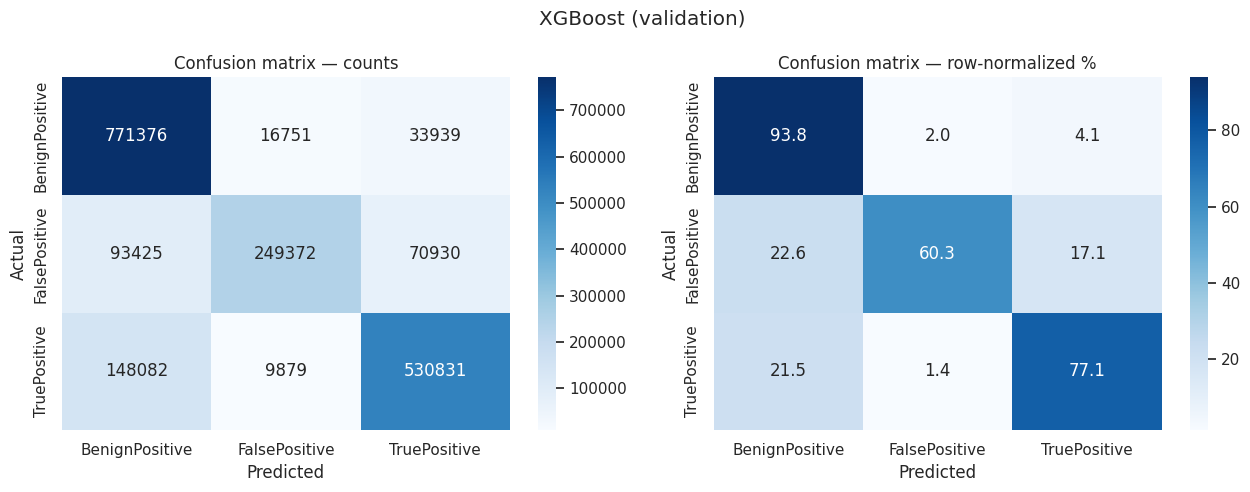

In [8]:
y_pred = model.predict(X_val)
y_proba = model.predict_proba(X_val)

accuracy = accuracy_score(y_val, y_pred)
macro_f1 = f1_score(y_val, y_pred, average='macro')
weighted_f1 = f1_score(y_val, y_pred, average='weighted')

labels_order = sorted(inv_target_map)
label_names = [inv_target_map[i] for i in labels_order]

report_dict = classification_report(
    y_val, y_pred, labels=labels_order, target_names=label_names, output_dict=True
)
print(classification_report(y_val, y_pred, labels=labels_order, target_names=label_names))
print(f'Accuracy: {accuracy:.4f}  Macro-F1: {macro_f1:.4f}  Weighted-F1: {weighted_f1:.4f}')
print(f'Best iteration: {best_iteration}  Training time: {training_time:.1f}s')

cm = confusion_matrix(y_val, y_pred, labels=labels_order)
cm_pct = cm / cm.sum(axis=1, keepdims=True) * 100

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=label_names, yticklabels=label_names, ax=axes[0])
axes[0].set_xlabel('Predicted'); axes[0].set_ylabel('Actual'); axes[0].set_title('Confusion matrix — counts')
sns.heatmap(cm_pct, annot=True, fmt='.1f', cmap='Blues', xticklabels=label_names, yticklabels=label_names, ax=axes[1])
axes[1].set_xlabel('Predicted'); axes[1].set_ylabel('Actual'); axes[1].set_title('Confusion matrix — row-normalized %')
fig.suptitle('XGBoost (validation)')
plt.tight_layout()
plt.savefig(f'{OUT_DIR}/confusion_matrix.png', dpi=120)
plt.show()

## 8. Additional graphs: per-class P/R/F1, loss curves, feature importance

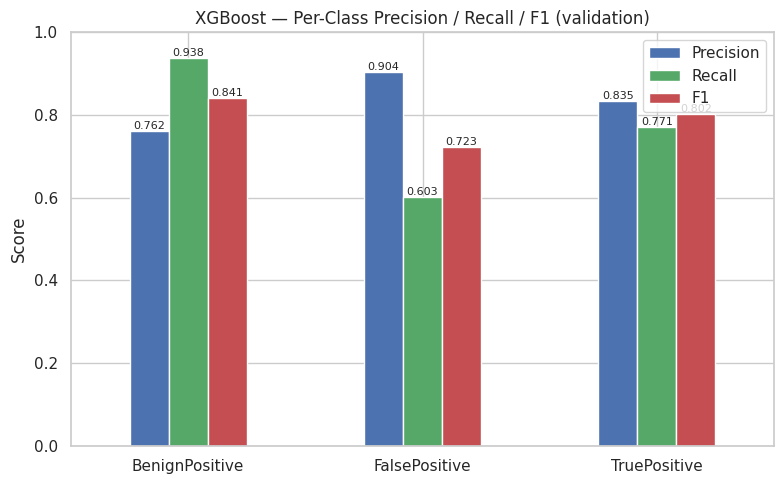

In [9]:
per_class_df = pd.DataFrame({
    'Precision': [report_dict[c]['precision'] for c in label_names],
    'Recall': [report_dict[c]['recall'] for c in label_names],
    'F1': [report_dict[c]['f1-score'] for c in label_names],
}, index=label_names)

ax = per_class_df.plot(kind='bar', figsize=(8, 5), rot=0, color=['#4C72B0', '#55A868', '#C44E52'])
ax.set_ylim(0, 1)
ax.set_ylabel('Score')
ax.set_title('XGBoost — Per-Class Precision / Recall / F1 (validation)')
for container in ax.containers:
    ax.bar_label(container, fmt='%.3f', fontsize=8)
plt.tight_layout()
plt.savefig(f'{OUT_DIR}/per_class_prf1.png', dpi=120)
plt.show()

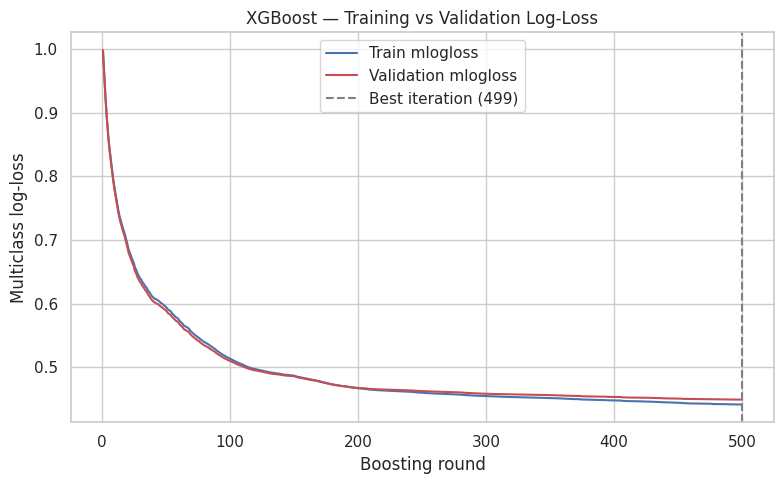

In [10]:
train_logloss = evals_result['validation_0']['mlogloss']
val_logloss = evals_result['validation_1']['mlogloss']
rounds = np.arange(1, len(train_logloss) + 1)

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(rounds, train_logloss, label='Train mlogloss', color='#4C72B0')
ax.plot(rounds, val_logloss, label='Validation mlogloss', color='#C44E52')
ax.axvline(best_iteration + 1, color='gray', linestyle='--', label=f'Best iteration ({best_iteration})')
ax.set_xlabel('Boosting round')
ax.set_ylabel('Multiclass log-loss')
ax.set_title('XGBoost — Training vs Validation Log-Loss')
ax.legend()
plt.tight_layout()
plt.savefig(f'{OUT_DIR}/logloss_curve.png', dpi=120)
plt.show()

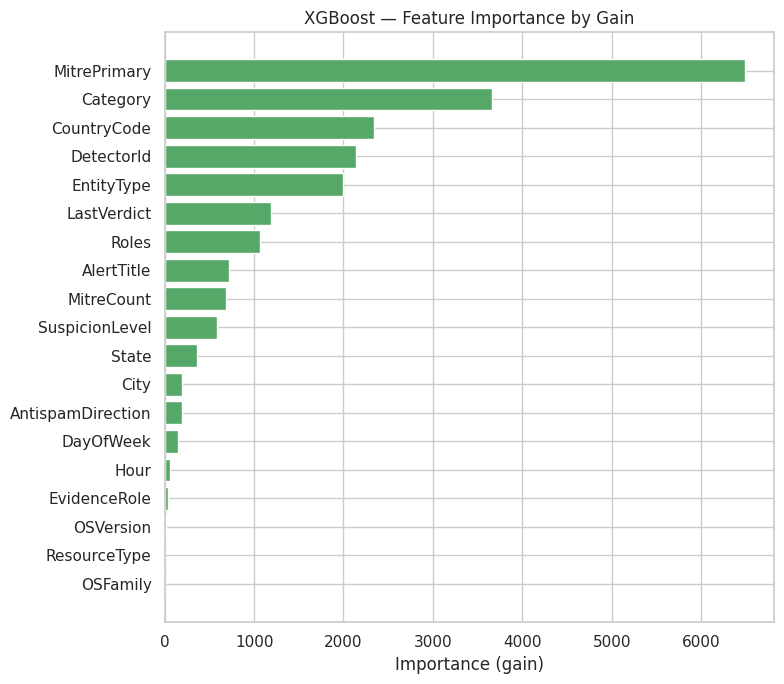

Top 10 features by gain:
MitrePrimary      6491.272949
Category          3656.680176
CountryCode       2344.206055
DetectorId        2141.104980
EntityType        1999.329590
LastVerdict       1186.089722
Roles             1067.500122
AlertTitle         719.297363
MitreCount         685.967957
SuspicionLevel     581.247986
dtype: float64


In [11]:
gain_scores = model.get_booster().get_score(importance_type='gain')
imp_series = pd.Series(gain_scores).reindex(FEATURES).fillna(0.0).sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(8, 7))
ax.barh(imp_series.index[::-1], imp_series.values[::-1], color='#55A868')
ax.set_xlabel('Importance (gain)')
ax.set_title('XGBoost — Feature Importance by Gain')
plt.tight_layout()
plt.savefig(f'{OUT_DIR}/feature_importance_gain.png', dpi=120)
plt.show()

print('Top 10 features by gain:')
print(imp_series.head(10))

## 9. Save model, metadata, results, evaluation history, and validation probabilities

In [12]:
model.save_model(f'{OUT_DIR}/xgboost_model.json')
model.get_booster().save_model(f'{OUT_DIR}/xgboost_model.ubj')
joblib.dump(model, f'{OUT_DIR}/xgboost_model.pkl')

with open(f'{OUT_DIR}/classification_report.json', 'w') as f:
    json.dump(report_dict, f, indent=2)

preprocessing_info = {
    'features': FEATURES,
    'cat_features': CAT_FEATURES,
    'numeric_features': NUMERIC_FEATURES,
    'categorical_cols_from_lightgbm': CATEGORICAL_COLS,
    'numeric_cols_from_lightgbm': NUMERIC_COLS,
    'excluded_id_cols': ID_LIKE_COLS,
    'excluded_leakage_cols': LEAKAGE_COLS,
    'reviewed_kept_cols': ['SuspicionLevel', 'LastVerdict'],
    'reviewed_kept_cols_note': 'Assumption carried over unchanged from the LightGBM notebook; '
                               'prediction-time availability of these verdict columns is not '
                               're-verified here and remains an open/unresolved question.',
    'group_cols': GROUP_COLS,
    'target_map': target_map,
    'categorical_encoding': 'pandas category dtype, categories fit on training split only; '
                             'unseen validation categories become missing (NaN), handled '
                             'natively by XGBoost hist tree method same as numeric NaNs.',
    'missing_value_placeholder_for_categoricals_before_dtype_cast': 'Missing',
    'reused_split_source': 'guide-lightgbm-baseline/split_assignment.csv',
    'reused_feature_audit_source': 'guide-lightgbm-baseline/preprocessing_info.json',
}
with open(f'{OUT_DIR}/preprocessing_info.json', 'w') as f:
    json.dump(preprocessing_info, f, indent=2)

model_params = model.get_params()
with open(f'{OUT_DIR}/xgboost_params.json', 'w') as f:
    json.dump(model_params, f, indent=2, default=str)

with open(f'{OUT_DIR}/evals_result.json', 'w') as f:
    json.dump(evals_result, f, indent=2)

results = {
    'xgboost_version': XGB_VERSION_STR,
    'early_stopping_api_used': early_stopping_api,
    'dataset_rows_after_cleaning': int(len(df)),
    'train_rows': int(train_mask.sum()),
    'val_rows': int(val_mask.sum()),
    'n_features': len(FEATURES),
    'n_cat_features': len(CAT_FEATURES),
    'n_numeric_features': len(NUMERIC_FEATURES),
    'training_time_seconds': round(training_time, 1),
    'n_estimators_requested': 500,
    'best_iteration': best_iteration,
    'early_stopping_rounds': 50,
    'tree_method': 'hist',
    'device_actual': str(device_actual),
    'accuracy': round(float(accuracy), 4),
    'macro_f1': round(float(macro_f1), 4),
    'weighted_f1': round(float(weighted_f1), 4),
    'per_class_report': report_dict,
    'confusion_matrix': cm.tolist(),
    'target_classes_order': label_names,
}
with open(f'{OUT_DIR}/results.json', 'w') as f:
    json.dump(results, f, indent=2)

val_predictions = val_row_ids.copy()
for i, cls in enumerate(label_names):
    val_predictions[f'proba_{cls}'] = y_proba[:, i]
val_predictions['y_true'] = y_val.reset_index(drop=True).map(inv_target_map)
val_predictions['y_pred'] = pd.Series(y_pred).map(inv_target_map)
val_predictions.to_csv(f'{OUT_DIR}/val_predictions.csv', index=False)

lap('Saved xgboost_model.json/.ubj/.pkl, preprocessing_info.json, xgboost_params.json, evals_result.json, '
    'results.json, classification_report.json, confusion_matrix.png, per_class_prf1.png, '
    'logloss_curve.png, feature_importance_gain.png, val_predictions.csv')
print(json.dumps({k: v for k, v in results.items() if k not in ('per_class_report', 'confusion_matrix')}, indent=2))

[ 2643.8s] Saved xgboost_model.json/.ubj/.pkl, preprocessing_info.json, xgboost_params.json, evals_result.json, results.json, classification_report.json, confusion_matrix.png, per_class_prf1.png, logloss_curve.png, feature_importance_gain.png, val_predictions.csv
{
  "xgboost_version": "3.4.1",
  "early_stopping_api_used": "constructor (XGBClassifier(early_stopping_rounds=...))",
  "dataset_rows_after_cleaning": 9442956,
  "train_rows": 7518371,
  "val_rows": 1924585,
  "n_features": 19,
  "n_cat_features": 16,
  "n_numeric_features": 3,
  "training_time_seconds": 2101.7,
  "n_estimators_requested": 500,
  "best_iteration": 499,
  "early_stopping_rounds": 50,
  "tree_method": "hist",
  "device_actual": "None",
  "accuracy": 0.8062,
  "macro_f1": 0.7885,
  "weighted_f1": 0.8014,
  "target_classes_order": [
    "BenignPositive",
    "FalsePositive",
    "TruePositive"
  ]
}


## 10. Summary & limitations

- Dataset, cleaning, leakage review, and train/validation split are all **reused exactly** from `guide-lightgbm-baseline` (verified: row counts match after the split lookup, and `(OrgId, IncidentId)` group overlap between train/val is re-checked as zero here).
- Same 19 audited raw features as the other three baselines. XGBoost uses its own native categorical handling (`enable_categorical=True` with pandas `category` dtype) directly — no one-hot encoding, no manual scaling — with category mappings fit on the training split only and unseen validation categories mapped to missing (handled the same way as native numeric NaNs).
- `SuspicionLevel`/`LastVerdict` prediction-time availability remains an **unresolved, unverified assumption** carried over from the other three notebooks — flagged again here rather than re-litigated, since re-auditing it was out of scope for this task.
- All hyperparameters (`n_estimators=500`, `learning_rate=0.1`, `max_depth=6`, `tree_method='hist'`) are exactly as specified by the task — no hyperparameter search was performed.
- `early_stopping_rounds=50` with `eval_set` means training may have stopped well before the requested `n_estimators=500` cap — see `results.json` for the actual `best_iteration` reached, and `early_stopping_api_used` for which XGBoost API this installed version required.
- `tree_method='hist'` was explicitly requested as the CPU-compatible histogram algorithm (`enable_gpu=false` in this kernel's metadata, so no GPU was ever available to fall back to or report); `device_actual` in `results.json` records whatever this XGBoost version reports for that setting.
- The official test set was not touched in this notebook.